##  Diplomado en Ciencia de Datos

<h1 align = 'center'> SHAP values: interpretabilidad de modelos </h1>

Los modelos más precisos (bosques aleatorios, *boosting*, redes neuronales) suelen ser también los más difíciles de interpretar. Saber que un modelo acierta no basta cuando debemos justificar una decisión: ¿por qué se rechazó este crédito?, ¿por qué el modelo cree que este tumor es maligno? **SHAP** (*SHapley Additive exPlanations*) responde esas preguntas asignando a cada variable una contribución numérica a cada predicción individual, con una base teórica sólida proveniente de la teoría de juegos cooperativos. Al agregar las explicaciones individuales obtenemos además una visión global del comportamiento del modelo.

En este cuaderno veremos la intuición y la formulación de los valores de Shapley, los calcularemos "a mano" para verificar que entendemos qué hace la librería, y luego usaremos `shap` en modelos lineales, de árboles y agnósticos al modelo, tanto en regresión como en clasificación.

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn shap

/home/juanf/Projects/Material-Ciencia-de-Datos/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from itertools import combinations
from math import factorial

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, accuracy_score

import warnings

warnings.filterwarnings('ignore')
shap.initjs()

/home/juanf/Projects/Material-Ciencia-de-Datos/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<h2> Motivación: ¿qué nos dice la importancia de variables clásica? </h2>

En los cuadernos de árboles y ensambles vimos el atributo `feature_importances_`. Tiene tres limitaciones importantes:

1. **Es global**: resume el modelo completo, pero no explica por qué se predijo un valor concreto para una observación concreta.
2. **No tiene signo**: nos dice que `bmi` importa, pero no si valores altos de `bmi` aumentan o disminuyen la predicción.
3. **Puede ser engañosa**: la importancia basada en impureza favorece variables con muchos valores distintos y se calcula sobre los datos de entrenamiento.

SHAP resuelve las tres: produce una explicación **local** (por observación), con **signo** y **magnitud**, y las explicaciones locales se pueden promediar para obtener una importancia **global** consistente.

<h2> Valores de Shapley </h2>

Lloyd Shapley propuso en 1953 una forma justa de repartir la ganancia de un equipo entre sus jugadores. Trasladado a aprendizaje automático:

- el **juego** es la predicción de una observación $\mathbf{x}$,
- los **jugadores** son las $p$ variables,
- la **ganancia** a repartir es la diferencia entre la predicción $f(\mathbf{x})$ y la predicción promedio $\mathbb{E}[f(\mathbf{X})]$.

Sea $F = \{1, \dots, p\}$ el conjunto de variables y $v(S)$ el valor de una coalición $S \subseteq F$, es decir, la predicción esperada cuando solo conocemos las variables en $S$:

$$v(S) = \mathbb{E}\big[ f(\mathbf{X}) \mid \mathbf{X}_S = \mathbf{x}_S \big]$$

El valor de Shapley de la variable $i$ es su contribución marginal promedio sobre todas las coaliciones posibles:

$$\phi_i = \sum_{S \subseteq F \setminus \{i\}} \frac{|S|! \, (p - |S| - 1)!}{p!} \Big[ v(S \cup \{i\}) - v(S) \Big]$$

El factor que multiplica a la contribución marginal es la probabilidad de que, al ordenar las variables al azar, justo las variables de $S$ lleguen antes que $i$.

<h3> Propiedades </h3>

Los valores de Shapley son la **única** asignación que cumple simultáneamente:

| Propiedad | Significado |
|---|---|
| Eficiencia | $\sum_{i=1}^{p} \phi_i = f(\mathbf{x}) - \phi_0$, con $\phi_0 = \mathbb{E}[f(\mathbf{X})]$ |
| Simetría | Dos variables que aportan lo mismo a toda coalición reciben el mismo valor |
| Jugador nulo | Una variable que nunca cambia la predicción recibe $\phi_i = 0$ |
| Aditividad | Para un ensamble $f = f_1 + f_2$, $\phi_i(f) = \phi_i(f_1) + \phi_i(f_2)$ |

<h3> Explicación aditiva </h3>

La eficiencia hace que SHAP sea un **modelo de explicación aditivo**: la predicción se descompone como

$$f(\mathbf{x}) = \phi_0 + \sum_{i=1}^{p} \phi_i$$

donde $\phi_0$ es el valor base (la predicción promedio) y cada $\phi_i$ empuja la predicción hacia arriba o hacia abajo desde ese valor base.

El costo de la definición es evidente: hay $2^p$ coaliciones. La librería `shap` ofrece algoritmos que evitan ese costo, algunos exactos para familias específicas de modelos (`LinearExplainer`, `TreeExplainer`) y otros aproximados para cualquier modelo (`KernelExplainer`, `PermutationExplainer`).

<h2> Datos y modelos </h2>

Usaremos el conjunto de datos de diabetes de `scikit-learn`: 442 pacientes, 10 variables (edad, sexo, índice de masa corporal `bmi`, presión arterial `bp` y seis mediciones de suero sanguíneo `s1`–`s6`, todas estandarizadas) y como objetivo una medida cuantitativa de la progresión de la enfermedad un año después.

In [3]:
diabetes = load_diabetes(as_frame=True)
X = diabetes['data']
y = diabetes['target']
X

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

<h2> SHAP en un modelo lineal </h2>

El caso más simple es una regresión lineal $f(\mathbf{x}) = \beta_0 + \sum_i \beta_i x_i$. Si las variables son independientes, el valor de Shapley tiene forma cerrada:

$$\phi_i = \beta_i \, \big(x_i - \mathbb{E}[X_i]\big)$$

Es decir, el coeficiente multiplicado por cuánto se desvía la observación del promedio. Verifiquémoslo.

In [5]:
lin = LinearRegression().fit(X_train, y_train)
print(f'R² en prueba: {r2_score(y_test, lin.predict(X_test)):.3f}')

R² en prueba: 0.453


In [6]:
explainer_lin = shap.LinearExplainer(lin, X_train)
shap_lin = explainer_lin(X_test)

Background dataset has 353 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=353 when initializing the masker.


In [7]:
# Comparación con la fórmula cerrada para la primera observación de prueba
manual = lin.coef_ * (X_test.iloc[0] - X_train.mean())

pd.DataFrame({'fórmula cerrada': manual, 'shap': shap_lin.values[0]})

,fórmula cerrada,shap
age,1.663955,1.962051
sex,10.846180,10.379010
bmi,-4.307759,-3.361659
bp,-5.972983,-3.683095
s1,-116.970979,-116.415425
s2,65.277976,64.587169
s3,3.297162,3.561787
s4,9.342171,9.387414
s5,22.981379,23.691276
s6,-0.346088,-0.510046


Los valores coinciden. Observa también que la suma de los $\phi_i$ más el valor base reconstruye la predicción del modelo (propiedad de eficiencia).

In [8]:
print('Valor base      :', shap_lin.base_values[0])
print('Suma de SHAP    :', shap_lin.values[0].sum())
print('Base + suma     :', shap_lin.base_values[0] + shap_lin.values[0].sum())
print('Predicción lin. :', lin.predict(X_test.iloc[[0]])[0])

Valor base      : 149.94907457852128
Suma de SHAP    : -10.40151617472516
Base + suma     : 139.54755840379613
Predicción lin. : 139.5475584037961


<h2> Cálculo exacto desde la definición </h2>

Para un modelo no lineal no hay fórmula tan sencilla, pero con $p = 10$ variables sí podemos enumerar las $2^{10} = 1024$ coaliciones. Entrenemos un `GradientBoostingRegressor` e implementemos la definición.

Para estimar $v(S)$ usamos un conjunto de datos de **fondo** (*background*): fijamos las variables de $S$ en los valores de $\mathbf{x}$, tomamos las demás de cada fila del fondo y promediamos las predicciones. Esta es la versión *intervencional* de la esperanza condicional.

In [9]:
gbr = GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
gbr.fit(X_train, y_train)

print(f'R² en entrenamiento: {gbr.score(X_train, y_train):.3f}')
print(f'R² en prueba       : {gbr.score(X_test, y_test):.3f}')

R² en entrenamiento: 0.830
R² en prueba       : 0.465


In [10]:
def shapley_exacto(modelo, x, fondo):
    """Valores de Shapley exactos de una observación `x` (pd.Series) usando `fondo` (pd.DataFrame)."""
    columnas = list(x.index)
    p = len(columnas)

    # v(S) para todas las coaliciones S (se calcula una sola vez)
    v = {}
    for k in range(p + 1):
        for S in combinations(range(p), k):
            Z = fondo.copy()
            for j in S:
                Z[columnas[j]] = x[columnas[j]]
            v[frozenset(S)] = modelo.predict(Z).mean()

    phi = np.zeros(p)
    for i in range(p):
        resto = [j for j in range(p) if j != i]
        for k in range(p):
            peso = factorial(k) * factorial(p - k - 1) / factorial(p)
            for S in combinations(resto, k):
                phi[i] += peso * (v[frozenset(S) | {i}] - v[frozenset(S)])

    return pd.Series(phi, index=columnas), v[frozenset()]

In [11]:
fondo = X_train.sample(100, random_state=0)
obs = X_test.iloc[0]

phi_manual, base_manual = shapley_exacto(gbr, obs, fondo)
phi_manual

age     4.784859
sex     5.549663
bmi    -7.127337
bp     -2.779251
s1    -17.499161
s2      2.472827
s3      8.050823
s4     -0.755880
s5     13.359861
s6     -1.164391
dtype: float64

Comparemos con la librería. `shap.explainers.Exact` es un explicador agnóstico al modelo que también enumera todas las coaliciones, así que debe coincidir con nuestra implementación. Incluimos además `TreeExplainer` con su configuración por defecto (sin fondo), que no enumera nada: usa la estructura de los árboles.

In [12]:
exacto = shap.explainers.Exact(gbr.predict, shap.maskers.Independent(fondo, max_samples=100))
phi_exacto = exacto(X_test.iloc[[0]])

phi_tree = shap.TreeExplainer(gbr)(X_test.iloc[[0]])

pd.DataFrame({
    'nuestra implementación': phi_manual,
    'shap Exact': phi_exacto.values[0],
    'TreeExplainer': phi_tree.values[0],
})

,nuestra implementación,shap Exact,TreeExplainer
age,4.784859,4.784859,5.990390
sex,5.549663,5.549663,4.962175
bmi,-7.127337,-7.127337,-11.707795
bp,-2.779251,-2.779251,-6.046600
s1,-17.499161,-17.499161,-16.938621
s2,2.472827,2.472827,3.126267
s3,8.050823,8.050823,8.667082
s4,-0.755880,-0.755880,-0.144341
s5,13.359861,13.359861,16.835624
s6,-1.164391,-1.164391,-1.569806


In [13]:
print('Diferencia máxima con shap Exact:', np.abs(phi_manual.values - phi_exacto.values[0]).max())
print('Predicción del modelo        :', gbr.predict(X_test.iloc[[0]])[0])
print('Valor base + suma de Shapley :', base_manual + phi_manual.sum())

Diferencia máxima con shap Exact: 5.3290705182007514e-14
Predicción del modelo        : 156.91091918975437
Valor base + suma de Shapley : 156.9109191897544


Nuestra implementación coincide con `Exact` (hasta error numérico) y reconstruye la predicción. `TreeExplainer` entrega valores del mismo orden y con casi todos los signos iguales, pero no idénticos: estima la esperanza condicional $v(S)$ siguiendo las rutas del propio árbol en lugar de usar un fondo, y su ventaja es que lo hace en tiempo polinomial en lugar de exponencial. Por eso es el explicador de elección para modelos de árboles aun con cientos de variables.

<h2> Explicaciones locales: una predicción </h2>

Ahora usamos el explicador por defecto sobre todo el conjunto de prueba. Sin fondo explícito, `TreeExplainer` usa la perturbación basada en la ruta del árbol (*tree path dependent*), que no necesita datos de fondo.

In [14]:
explainer = shap.Explainer(gbr)
shap_values = explainer(X_test)

print(type(explainer).__name__)
print('Forma de los valores SHAP:', shap_values.values.shape)
print('Valor base:', shap_values.base_values[0])

TreeExplainer
Forma de los valores SHAP: (89, 10)
Valor base: 153.7365439093485


El objeto `Explanation` contiene `.values` (las contribuciones), `.base_values` (el promedio de predicciones) y `.data` (los valores originales de las variables). El **gráfico de cascada** (*waterfall*) muestra cómo cada variable empuja la predicción desde el valor base hasta la predicción final: en rojo las que la aumentan y en azul las que la disminuyen.

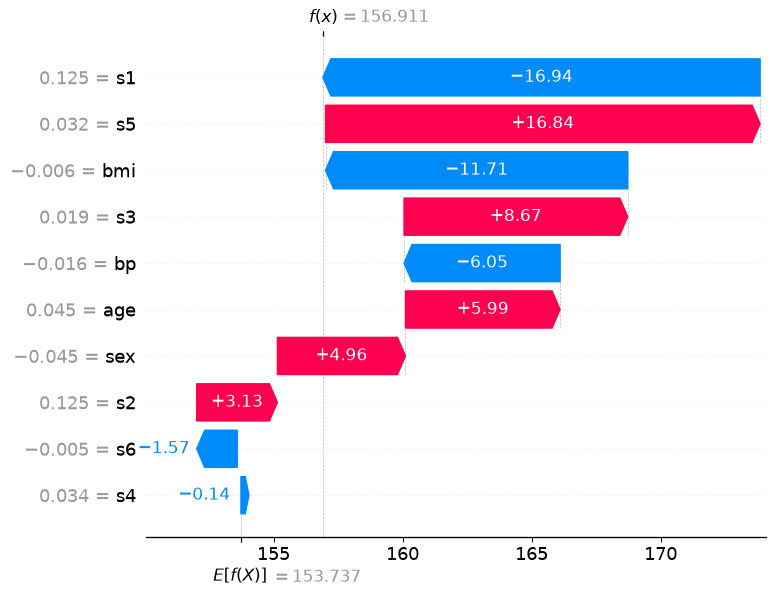

In [15]:
shap.plots.waterfall(shap_values[0])

Veamos un caso con una predicción muy diferente, el paciente con mayor progresión predicha:

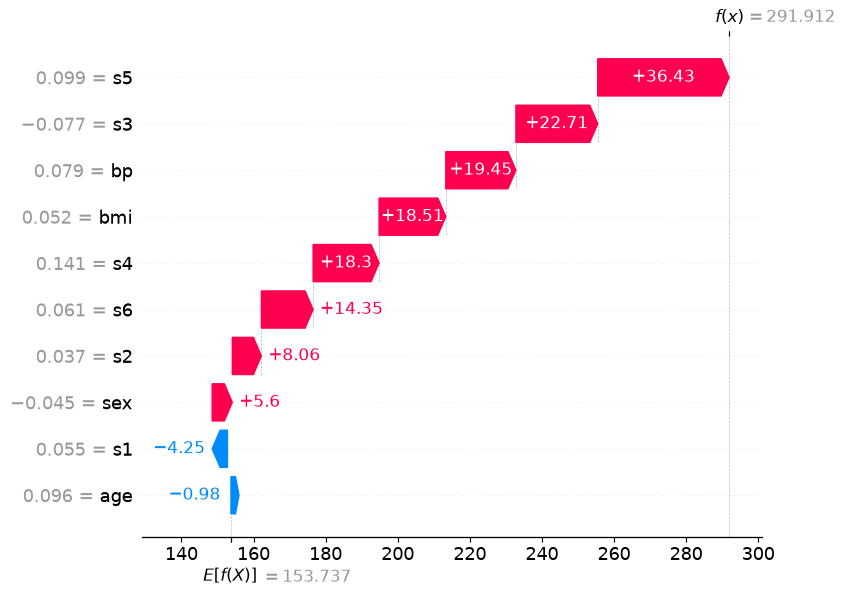

In [16]:
idx_max = np.argmax(gbr.predict(X_test))
shap.plots.waterfall(shap_values[idx_max])

El gráfico de fuerza (*force plot*) presenta la misma información de forma compacta. Es útil para comparar varias observaciones: al apilar muchos de ellos obtenemos una vista interactiva de todo el conjunto.

In [17]:
shap.plots.force(shap_values[0])

<h2> Explicaciones globales </h2>

Al agregar los valores SHAP de todas las observaciones obtenemos la importancia global del modelo. La versión más sencilla es el promedio del valor absoluto:

$$I_i = \frac{1}{n} \sum_{k=1}^{n} \left| \phi_i^{(k)} \right|$$

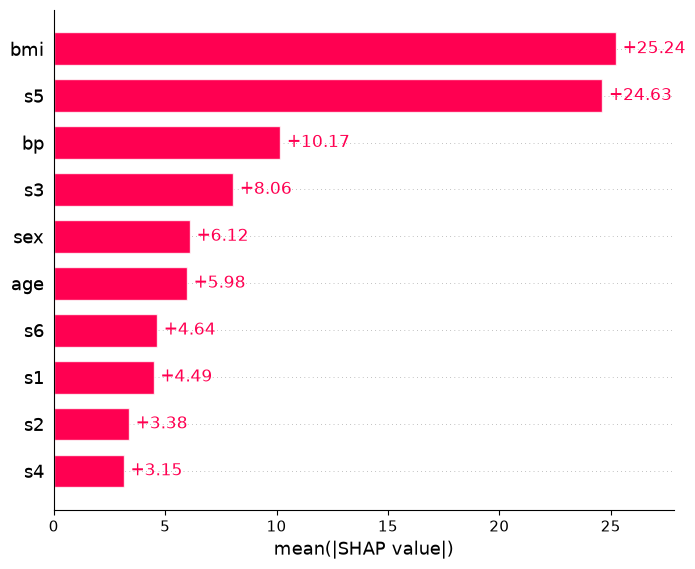

In [18]:
shap.plots.bar(shap_values)

El gráfico de barras pierde la información del signo. El **gráfico de enjambre** (*beeswarm*) conserva todo: cada punto es una observación, la posición horizontal es su valor SHAP y el color indica si el valor de la variable es alto (rojo) o bajo (azul). Las variables se ordenan por importancia global.

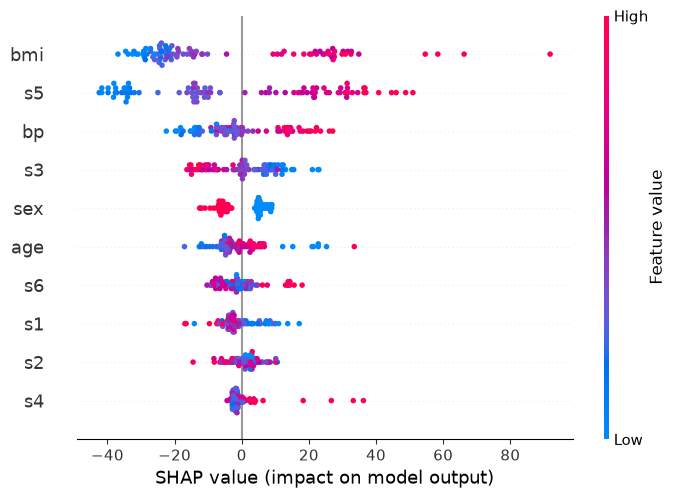

In [19]:
shap.plots.beeswarm(shap_values)

Cómo leerlo: en `bmi`, los puntos rojos (índice de masa corporal alto) están a la derecha, así que un `bmi` alto aumenta la progresión predicha de la enfermedad. En `s5` ocurre algo similar. Las variables con puntos concentrados cerca de cero casi no influyen en el modelo.

<h2> Gráficos de dependencia </h2>

Para entender **cómo** una variable afecta la predicción graficamos su valor contra su valor SHAP. Si además coloreamos por otra variable, podemos detectar interacciones.

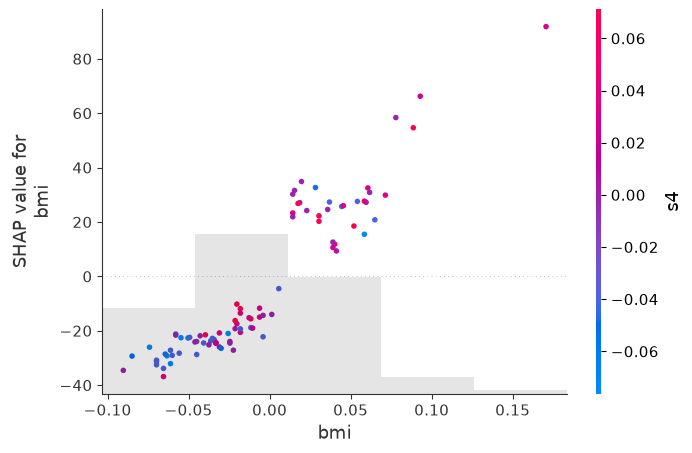

In [20]:
shap.plots.scatter(shap_values[:, 'bmi'], color=shap_values)

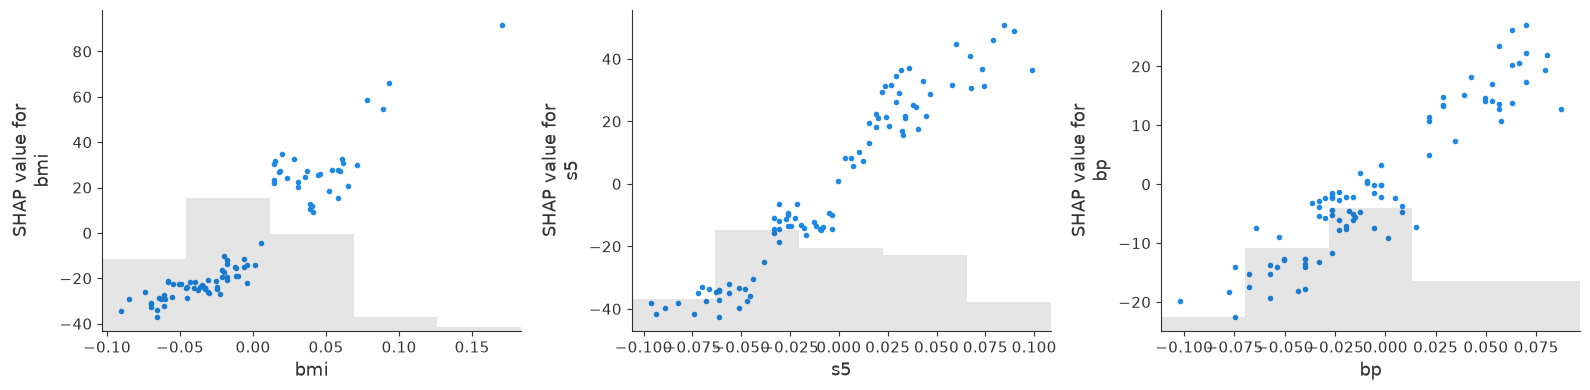

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ['bmi', 's5', 'bp']):
    shap.plots.scatter(shap_values[:, col], ax=a, show=False)
plt.tight_layout()
plt.show()

Estas curvas son el efecto de cada variable *según el modelo*, y pueden ser no lineales: algo que un coeficiente de regresión no puede mostrar.

<h2> Valores de interacción </h2>

Los valores SHAP asignan a cada variable un único número, pero a veces el efecto de una variable depende de otra. Los **valores de interacción de SHAP** descomponen la contribución en efectos principales ($\Phi_{ii}$) e interacciones por pares ($\Phi_{ij}$, $i \neq j$):

$$\phi_i = \Phi_{ii} + \sum_{j \neq i} \Phi_{ij}$$

`TreeExplainer` los calcula de forma exacta, a un costo mayor, por lo que usamos solo una parte de los datos.

In [22]:
explainer_int = shap.TreeExplainer(gbr)
inter = explainer_int.shap_interaction_values(X_test)
inter.shape

(89, 10, 10)

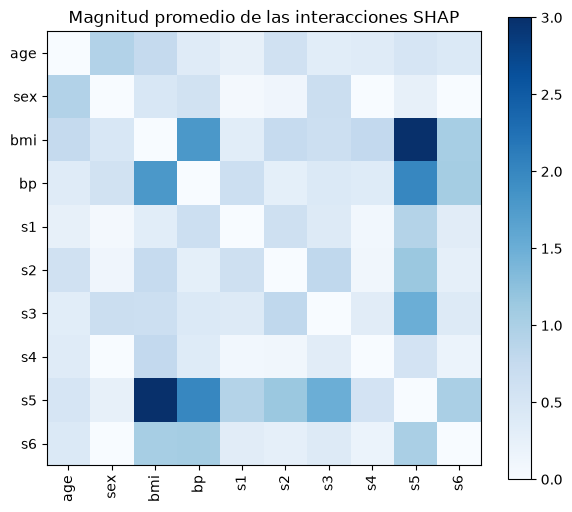

In [23]:
# Magnitud promedio de cada interacción (se anula la diagonal: efectos principales)
mag = np.abs(inter).mean(axis=0)
np.fill_diagonal(mag, 0)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(mag, cmap='Blues')
ax.set_xticks(range(X.shape[1]), X.columns, rotation=90)
ax.set_yticks(range(X.shape[1]), X.columns)
ax.set_title('Magnitud promedio de las interacciones SHAP')
fig.colorbar(im);

<h2> Comparación con otras medidas de importancia </h2>

Contrastemos tres formas de medir la importancia global en el mismo modelo: la basada en impureza de `scikit-learn`, la importancia por permutación (evaluada en datos de prueba) y la de SHAP.

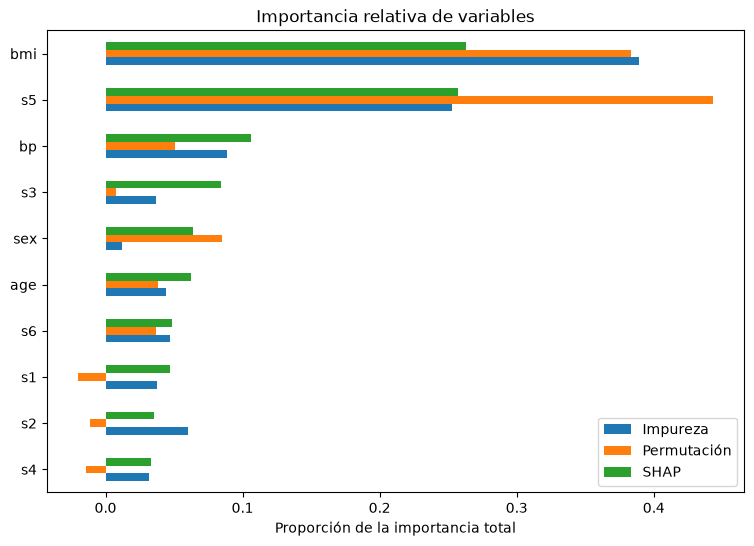

In [24]:
imp_impureza = pd.Series(gbr.feature_importances_, index=X.columns)

perm = permutation_importance(gbr, X_test, y_test, n_repeats=30, random_state=42)
imp_perm = pd.Series(perm.importances_mean, index=X.columns)

imp_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X.columns)

comparacion = pd.DataFrame({
    'Impureza': imp_impureza,
    'Permutación': imp_perm,
    'SHAP': imp_shap,
})
# Se normalizan para compararlas en la misma escala
(comparacion / comparacion.sum()).sort_values('SHAP').plot.barh(figsize=(9, 6))
plt.title('Importancia relativa de variables')
plt.xlabel('Proporción de la importancia total');

Las tres coinciden en las variables principales, pero pueden diferir en el resto. La ventaja de SHAP es que su importancia sale de explicaciones locales que suman exactamente la predicción, y que podemos descomponer cuando una variable es importante solo para un subgrupo de observaciones.

<h2> SHAP en clasificación </h2>

Para clasificación usamos el conjunto de cáncer de mama (ya visto en otros cuadernos) con las 30 variables y un `GradientBoostingClassifier`.

Un detalle importante: para modelos de *boosting* `TreeExplainer` explica la salida **antes** de la función logística, es decir, el *log-odds*. Los valores SHAP son aditivos en esa escala, y no en probabilidad.

In [25]:
cancer = load_breast_cancer(as_frame=True)
Xc = cancer['data']
yc = cancer['target']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)

gbc = GradientBoostingClassifier(n_estimators=150, max_depth=3, random_state=42)
gbc.fit(Xc_train, yc_train)

print(f'Exactitud en prueba: {accuracy_score(yc_test, gbc.predict(Xc_test)):.3f}')

Exactitud en prueba: 0.956


In [26]:
explainer_c = shap.Explainer(gbc)
shap_c = explainer_c(Xc_test)
shap_c.values.shape

(114, 30)

In [27]:
# Verificación en la escala log-odds, con la observación más incierta del modelo
obs_c = int(np.argmin(np.abs(gbc.predict_proba(Xc_test)[:, 1] - 0.5)))
log_odds = shap_c.base_values[obs_c] + shap_c.values[obs_c].sum()
prob = 1 / (1 + np.exp(-log_odds))

print(f'Base + suma SHAP (log-odds): {log_odds:.4f}')
print(f'Probabilidad implícita     : {prob:.4f}')
print(f'predict_proba (clase 1)    : {gbc.predict_proba(Xc_test.iloc[[obs_c]])[0, 1]:.4f}')

Base + suma SHAP (log-odds): 1.2143
Probabilidad implícita     : 0.7711
predict_proba (clase 1)    : 0.7711


Recuerda que en este conjunto la clase `1` es **benigno** y la `0` es **maligno**. Un valor SHAP positivo empuja hacia "benigno".

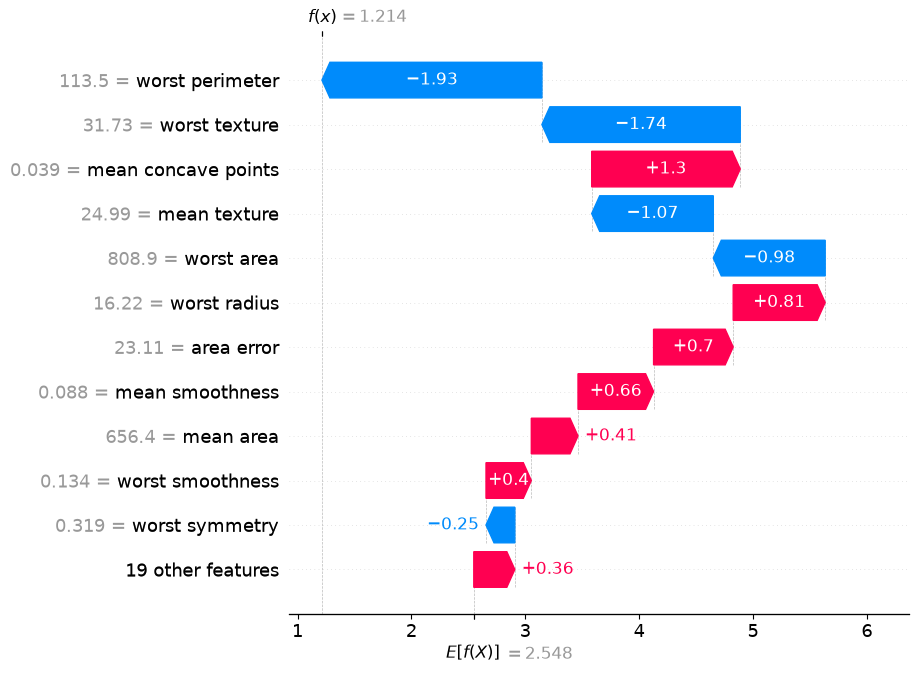

In [28]:
shap.plots.waterfall(shap_c[obs_c], max_display=12)

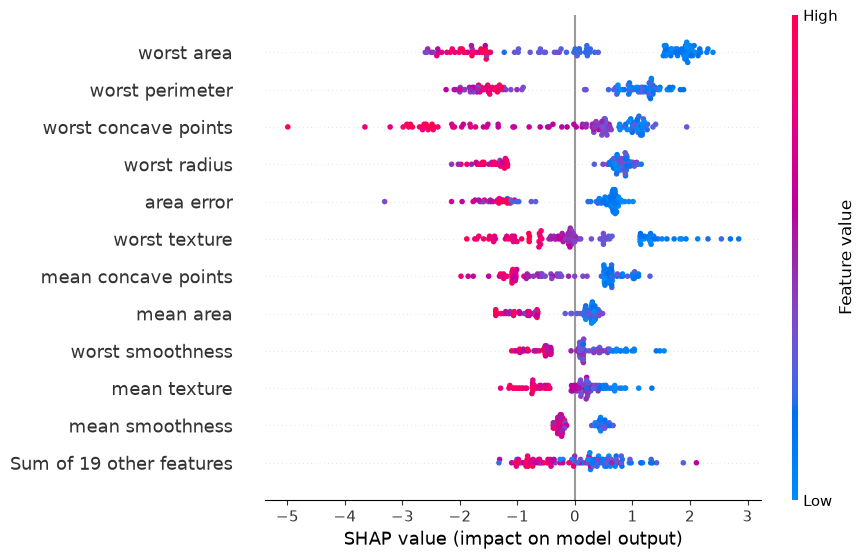

In [29]:
shap.plots.beeswarm(shap_c, max_display=12)

Si queremos explicar en la escala de probabilidad, podemos pasar el fondo y pedir la salida transformada con `model_output='probability'`. Esto requiere la perturbación intervencional.

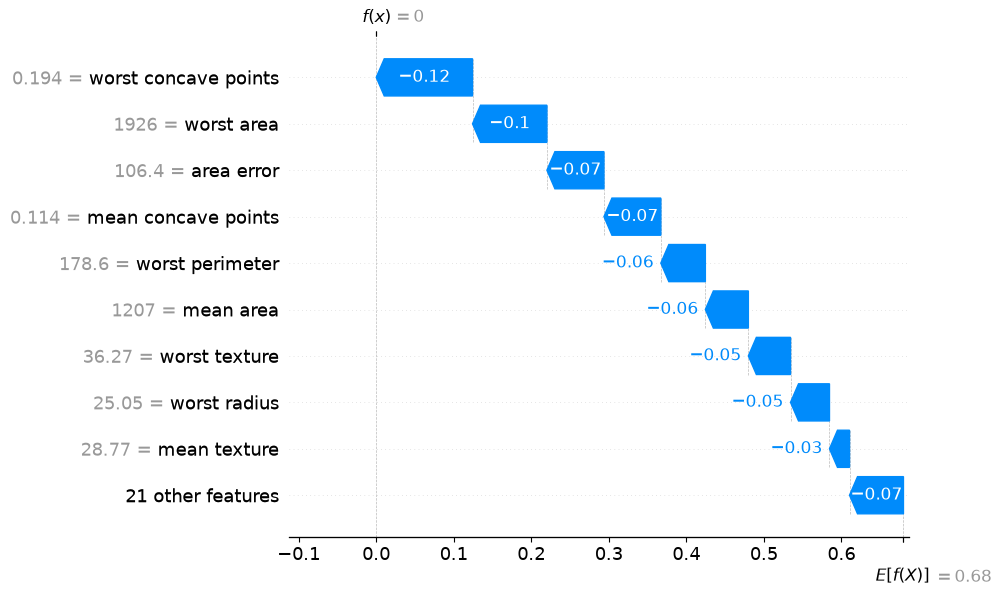

In [30]:
fondo_c = shap.sample(Xc_train, 100, random_state=0)

explainer_prob = shap.TreeExplainer(
    gbc, data=fondo_c,
    feature_perturbation='interventional',
    model_output='probability',
)
shap_prob = explainer_prob(Xc_test.iloc[:50])

shap.plots.waterfall(shap_prob[0], max_display=10)  # primera observación de prueba

<h2> Explicadores agnósticos al modelo </h2>

`TreeExplainer` y `LinearExplainer` están limitados a sus familias de modelos. Para cualquier otro (SVM, KNN, redes neuronales, *pipelines*) usamos `KernelExplainer`, que aproxima los valores de Shapley muestreando coaliciones y ajustando una regresión lineal ponderada. Solo necesita una función que reciba datos y devuelva predicciones.

Es mucho más lento, por lo que se recomienda resumir el fondo (por ejemplo con k-medias) y explicar pocas observaciones.

In [31]:
svm = make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))
svm.fit(Xc_train, yc_train)

print(f'Exactitud en prueba: {accuracy_score(yc_test, svm.predict(Xc_test)):.3f}')

Exactitud en prueba: 0.982


In [32]:
fondo_km = shap.kmeans(Xc_train, 10)

explainer_k = shap.KernelExplainer(lambda d: svm.predict_proba(d)[:, 1], fondo_km)
Xk = Xc_test.iloc[:20]
shap_k = shap.Explanation(
    values=explainer_k.shap_values(Xk, nsamples=500),
    base_values=np.repeat(explainer_k.expected_value, len(Xk)),
    data=Xk.values,
    feature_names=list(Xk.columns),
)

100%|██████████| 20/20 [00:00<00:00, 45.06it/s]


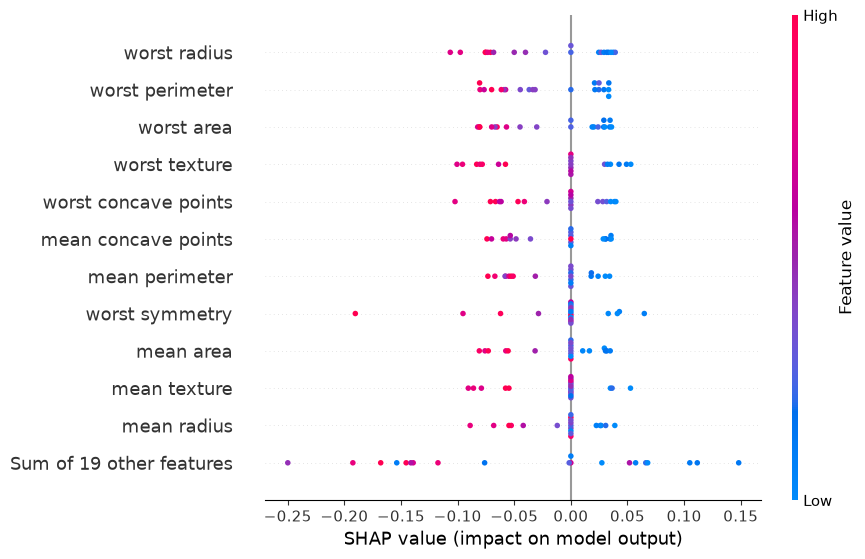

In [33]:
shap.plots.beeswarm(shap_k, max_display=12)

Aunque el modelo es completamente distinto, las variables más influyentes son similares a las del modelo de árboles. Esto da confianza de que la señal está en los datos y no en un artefacto del modelo.

<h2> ¿Fieles al modelo o fieles a los datos? </h2>

Hasta ahora definimos el valor de una coalición como $v(S) = \mathbb{E}[f(\mathbf{X}) \mid \mathbf{X}_S = \mathbf{x}_S]$ sin precisar **cómo** se calcula esa esperanza. Esa decisión importa mucho cuando las variables están correlacionadas, y es el tema del artículo *True to the Model or True to the Data?* (Chen, Janizek, Lundberg y Lee, 2020, [arXiv:2006.16234](https://arxiv.org/abs/2006.16234)).

Para "quitar" las variables que no están en $S$ hay dos opciones:

| | Fiel al modelo (*true to the model*) | Fiel a los datos (*true to the data*) |
|---|---|---|
| Esperanza usada | Marginal o **intervencional**: $\mathbb{E}_{\mathbf{X}_{\bar S}}\big[f(\mathbf{x}_S, \mathbf{X}_{\bar S})\big]$ | **Condicional** (observacional): $\mathbb{E}\big[f(\mathbf{X}) \mid \mathbf{X}_S = \mathbf{x}_S\big]$ |
| Qué hace con las variables ausentes | Las muestrea de forma independiente de $\mathbf{x}_S$, rompiendo las correlaciones | Las muestrea respetando su relación con $\mathbf{x}_S$ |
| Qué mide | Cuánto *usa* el modelo cada variable | Cuánta información sobre la salida aporta cada variable, usada o no por el modelo |
| En `shap` | `feature_perturbation='interventional'` (con fondo), `Independent` masker | `'correlation_dependent'`, *maskers* con imputación, o estimadores propios |

La idea central del artículo es que **ninguna es universalmente correcta**: responden preguntas distintas. Si queremos auditar o depurar el modelo, queremos saber qué hace él con sus entradas (fiel al modelo). Si usamos el modelo como una lente para aprender algo del fenómeno, por ejemplo qué factores se asocian con una enfermedad, queremos que variables correlacionadas compartan el crédito (fiel a los datos).

Ambas conservan la propiedad de eficiencia, pero se distinguen en lo que ocurre con las correlaciones:

- **Fiel al modelo** cumple "jugador nulo" en sentido estricto: si el modelo no usa una variable, su valor SHAP es cero. A cambio, evalúa el modelo en combinaciones de valores que pueden no existir en los datos.
- **Fiel a los datos** evita esas combinaciones irreales, pero puede asignar importancia a una variable que el modelo *nunca usa*, solo porque está correlacionada con otra que sí usa. Además, estimar esperanzas condicionales en dimensión alta es difícil y exige supuestos (por ejemplo, normalidad multivariada) que se convierten en una fuente de error.

<h3> Un ejemplo controlado </h3>

Generamos dos variables muy correlacionadas ($\rho = 0.95$) y un "modelo" que **solo usa $x_1$**: $f(\mathbf{x}) = 3 x_1$. Para calcular $v(S)$ bajo ambos enfoques escribimos una función genérica que recibe $v$ y devuelve los valores de Shapley.

In [34]:
def shapley_desde_v(v, p):
    """Valores de Shapley a partir de una función de valor v(S), con S una tupla de índices."""
    cache = {}
    def val(S):
        S = tuple(sorted(S))
        if S not in cache:
            cache[S] = v(S)
        return cache[S]

    phi = np.zeros(p)
    for i in range(p):
        resto = [j for j in range(p) if j != i]
        for k in range(p):
            peso = factorial(k) * factorial(p - k - 1) / factorial(p)
            for S in combinations(resto, k):
                phi[i] += peso * (val(S + (i,)) - val(S))
    return phi


def v_intervencional(f, x, fondo):
    """v(S): fija x_S y toma el resto de variables de filas del fondo (independientes de x_S)."""
    def v(S):
        Z = fondo.copy()
        for j in S:
            Z[:, j] = x[j]
        return f(Z).mean()
    return v


def v_condicional_gauss(w, x, mu, Sigma):
    """v(S) = E[w·X | X_S = x_S] para X ~ N(mu, Sigma) y un modelo lineal f(x) = w·x."""
    p = len(x)
    def v(S):
        S = list(S)
        C = [j for j in range(p) if j not in S]
        media_C = mu[C].copy()
        if S and C:
            media_C = media_C + Sigma[np.ix_(C, S)] @ np.linalg.solve(Sigma[np.ix_(S, S)], x[S] - mu[S])
        return (w[S] @ x[S] if S else 0.0) + (w[C] @ media_C if C else 0.0)
    return v

In [35]:
rng = np.random.default_rng(0)
rho = 0.95
Sigma_sint = np.array([[1, rho], [rho, 1]])
Z = rng.multivariate_normal([0, 0], Sigma_sint, size=2000)

w_sint = np.array([3.0, 0.0])          # el modelo ignora por completo a x2
f_sint = lambda D: D @ w_sint

x_obs = np.array([1.0, 1.0])
mu_sint = Z.mean(axis=0)
Sigma_hat = np.cov(Z, rowvar=False)

phi_modelo = shapley_desde_v(v_intervencional(f_sint, x_obs, Z), 2)
phi_datos = shapley_desde_v(v_condicional_gauss(w_sint, x_obs, mu_sint, Sigma_hat), 2)

pd.DataFrame({'Fiel al modelo': phi_modelo, 'Fiel a los datos': phi_datos}, index=['x1', 'x2'])

,Fiel al modelo,Fiel a los datos
x1,2.925536,1.546973
x2,0.000000,1.378563


El modelo ignora a $x_2$, y el enfoque *fiel al modelo* lo refleja: $\phi_2 = 0$. El enfoque *fiel a los datos* le asigna casi la mitad del crédito a $x_2$: si sabemos que $x_2 = 1$, es muy probable que $x_1$ también sea alto y, por tanto, que la predicción sea alta. Ninguno miente; contestan preguntas diferentes. Con $\rho \to 1$ el crédito se reparte por igual, y con $\rho = 0$ ambos enfoques coinciden.

<h3> Con los datos reales de diabetes </h3>

En los datos de diabetes hay variables de suero muy correlacionadas, como `s1` y `s2`:

In [36]:
corr = X_train.corr()
print(f"corr(s1, s2) = {corr.loc['s1', 's2']:.2f}")
print(f"corr(s1, s4) = {corr.loc['s1', 's4']:.2f}")
print(f"corr(s2, s4) = {corr.loc['s2', 's4']:.2f}")

corr(s1, s2) = 0.89
corr(s1, s4) = 0.55
corr(s2, s4) = 0.65


Repetimos la comparación con la regresión lineal `lin` entrenada antes. En un modelo lineal, el enfoque fiel al modelo tiene forma cerrada (la que ya verificamos), y el fiel a los datos se calcula suponiendo normalidad multivariada. Como contraste adicional, `LinearExplainer` implementa ese segundo enfoque con `feature_perturbation='correlation_dependent'`.

In [37]:
w = lin.coef_
mu = X_train.mean().values
Sigma = X_train.cov().values
x0 = X_test.iloc[0].values

phi_modelo = shapley_desde_v(v_intervencional(lin.predict, x0, X_train.values), 10)
phi_datos = shapley_desde_v(v_condicional_gauss(w, x0, mu, Sigma), 10)

explainer_corr = shap.LinearExplainer(lin, X_train, feature_perturbation='correlation_dependent')
phi_shap_corr = explainer_corr(X_test.iloc[[0]]).values[0]

comparacion_vd = pd.DataFrame({
    'Fiel al modelo': phi_modelo,
    'Fiel a los datos (nuestra implementación)': phi_datos,
    'LinearExplainer correlation_dependent': phi_shap_corr,
}, index=X.columns)
comparacion_vd

Estimating transforms: 100%|██████████| 1000/1000 [00:00<00:00, 6876.13it/s]


,Fiel al modelo,Fiel a los datos (nuestra implementación),LinearExplainer correlation_dependent
age,1.663955,3.976055,3.793838
sex,10.846180,7.432030,7.612853
bmi,-4.307759,-13.917779,-13.977171
bp,-5.972983,-11.661289,-11.615427
s1,-116.970979,3.026087,3.224314
s2,65.277976,-1.158409,-0.955005
s3,3.297162,-3.638928,-3.694765
s4,9.342171,-0.507654,-1.143138
s5,22.981379,7.273104,7.702407
s6,-0.346088,-5.012204,-5.136891


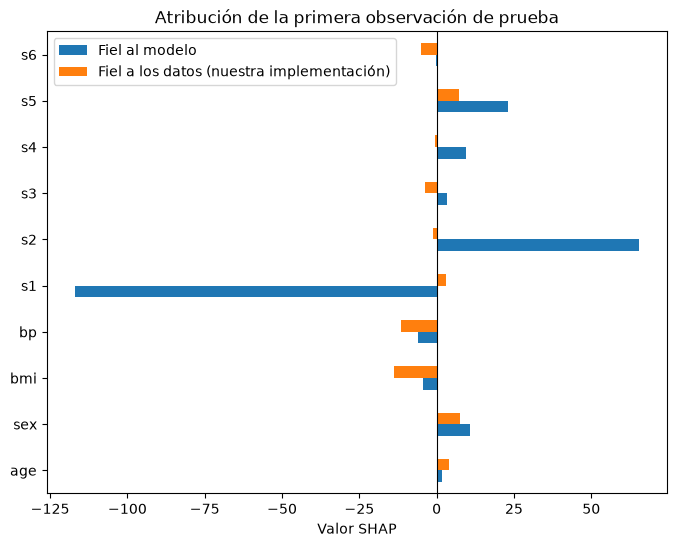

In [38]:
comparacion_vd[['Fiel al modelo', 'Fiel a los datos (nuestra implementación)']].plot.barh(figsize=(8, 6))
plt.axvline(0, color='k', lw=0.8)
plt.title('Atribución de la primera observación de prueba')
plt.xlabel('Valor SHAP');

La diferencia es drástica en `s1` y `s2` (correlación 0.89): el modelo lineal les asigna coeficientes grandes y de signo opuesto que casi se cancelan, y el enfoque fiel al modelo lo refleja con atribuciones enormes (alrededor de −117 y +65). Eso es *verdad sobre el modelo*, pero engañoso si quisiéramos concluir algo sobre los pacientes: ambas variables miden casi lo mismo. El enfoque fiel a los datos reparte la información compartida y las deja cerca de cero, y también cambian `bmi` y `bp`, que están correlacionadas con ellas. `LinearExplainer` con `correlation_dependent` da valores cercanos a los de nuestra implementación (no idénticos: estima la covarianza por su cuenta). La suma de las atribuciones es la misma en ambos enfoques, porque las dos cumplen la propiedad de eficiencia.

<h3> ¿Cuál elegir? </h3>

| Pregunta que queremos responder | Enfoque recomendado |
|---|---|
| ¿Qué variables está usando este modelo? ¿Está usando una variable sensible o con fuga de información? | Fiel al modelo |
| ¿Cómo cambiaría la predicción si interviniéramos sobre una variable? (atribución *causal* respecto al modelo, no al mundo) | Fiel al modelo |
| ¿Qué variables están asociadas con la salida, aunque el modelo prefiera usar otras equivalentes? | Fiel a los datos |
| Descubrimiento científico a partir de un modelo predictivo | Fiel a los datos |
| Sin fondo representativo, o con dimensión alta donde no podemos estimar bien la condicional | Fiel al modelo (más simple y estable de estimar) |

En la práctica, `TreeExplainer` por defecto y `KernelExplainer` con un fondo usan una esperanza marginal o intervencional, mientras que la versión por ruta del árbol de `TreeExplainer` sin fondo se comporta como una aproximación a la condicional. Por eso conviene declarar siempre qué enfoque se está usando al reportar valores SHAP.

<h2> Limitaciones y buenas prácticas </h2>

- **Explican al modelo, no al mundo.** SHAP dice qué variables usa el modelo para predecir, no qué causa el resultado. Un valor SHAP alto no implica causalidad.
- **Variables correlacionadas.** Con la perturbación intervencional se evalúan combinaciones de valores que pueden ser irreales (por ejemplo, un peso muy alto con una talla muy baja). El crédito se reparte entre variables correlacionadas de forma que puede ser contraintuitiva; conviene revisar la matriz de correlaciones o agrupar variables redundantes. La sección anterior explica cómo la elección entre esperanza intervencional y condicional cambia el reparto.
- **Dependencia del fondo.** El valor base y los valores SHAP dependen del conjunto de referencia. Elígelo representativo y documéntalo.
- **Escala de la explicación.** En clasificación con *boosting* los valores están en *log-odds*; no los interpretes como puntos de probabilidad sin transformarlos.
- **Costo computacional.** `TreeExplainer` y `LinearExplainer` son rápidos; `KernelExplainer` crece rápido con el número de variables y observaciones.
- **Úsalo con datos de prueba.** Explicar el entrenamiento puede reflejar sobreajuste; explicar datos no vistos muestra cómo se comporta el modelo en la práctica.

<h2> Ejercicios propuestos </h2>

1. Entrena un `RandomForestRegressor` sobre los datos de diabetes y compara su gráfico de enjambre con el de `GradientBoostingRegressor`. ¿Coinciden las variables más importantes y el signo de sus efectos?
2. Repite la comparación de importancias del apartado anterior con el modelo de cáncer de mama. ¿Qué variables cambian de posición entre impureza, permutación y SHAP?
3. Elimina de `X` la variable `s1` y `s2` (muy correlacionadas con `s4` y entre sí) y reentrena. ¿Cómo cambia el reparto de importancia entre las variables restantes?
4. Para una observación de `Xc_test` mal clasificada por el modelo, genera el gráfico de cascada y explica en palabras qué variables llevaron al error.